# Praktikum 08 — Inferensi Model dan Aplikasi Streamlit

**Studi Kasus Preeklamsia (PE) | Workshop From Data to Machine Learning**  
**Jenis:** praktikum terapan dengan notebook utama dan `app.py` untuk web interaktif.  
**Prasyarat:** Praktikum 05 (audit & cleaning), 06 (pipeline & evaluasi), 07 (ekspor dan model card).  
**Estimasi:** 90–120 menit untuk praktikum terstruktur, di luar diskusi dan instalasi.

> **Batas penggunaan:** Seluruh prediksi merupakan **demonstrasi pendidikan**. Model tidak tervalidasi untuk diagnosis, skrining medis, pengambilan keputusan klinis, ataupun estimasi risiko individual. Gunakan hanya input sintetis.

**Sumber:** Model Decision Tree final dari Praktikum 07, yang dipilih melalui cross-validation pada data training Praktikum 06. Notebook ini **tidak melakukan training ulang**, agar artefak model tetap konsisten.

## A. Tujuan pembelajaran dan orientasi
Setelah kegiatan ini mahasiswa mampu:
1. Menjelaskan perbedaan `fit`, `transform`, `predict`, dan `predict_proba`.
2. Memuat kembali pipeline final dan memeriksa kontrak delapan fitur.
3. Melakukan **inferensi satu baris dan batch** menggunakan contoh sintetis.
4. Memvalidasi nama kolom, tipe numerik, kategori, dan missing values.
5. Menjelaskan keterbatasan model, skor tidak terkalibrasi, dan evaluasi dengan label kelas langka.
6. Menjalankan aplikasi Streamlit dari `app.py` dan mencocokkan hasil dengan notebook.
7. Mengekspor prediksi, membuat smoke test, dan menyusun laporan singkat.

**Pertanyaan pemandu:** Bagaimana model yang sudah disimpan dapat digunakan kembali tanpa training ulang, tetapi tetap menerima fitur dengan struktur yang sama?

### A1. Keluaran praktikum
- `hasil_praktikum08/prediksi_contoh.csv`: batch inferensi dari data sintetis.
- `hasil_praktikum08/ringkasan_inferensi.json`: versi, jumlah baris, konfigurasi ringkas, dan checksum.
- `hasil_praktikum08/laporan_uji_08.csv`: hasil uji fungsional input.
- Web Streamlit yang menggunakan **artefak yang sama**, bukan model baru.

File di folder `hasil_praktikum08/` dihasilkan otomatis saat notebook dijalankan. Jangan masukkan informasi pribadi atau data klinis pasien.

## B. Alur inferensi yang benar

**Training (dikerjakan pada Modul 06)**: data train → imputer + encoder → Decision Tree → validasi model.

**Ekspor (Modul 07)**: seluruh pipeline + metadata → `.joblib` dan `model_card.json`.

**Inferensi (Modul 08)**: input baru → validasi kontrak → pipeline tersimpan → prediksi + skor keluaran → penjelasan keterbatasan.

Jangan memanggil `fit()` atau `fit_transform()` terhadap data baru. Parameter imputasi, vocabulary kategori, dan model harus menggunakan nilai yang dipelajari pada training. **Streamlit adalah antarmuka**, bukan algoritma klasifikasi.

## C. Persiapan environment dan path
Ekstrak ZIP lengkap, lalu buka notebook ini dari folder utama. Tiga artefak di bawah telah disertakan:
`deployment/versi_2_hasil_studi_kasus/models/pe_workshop_pipeline.joblib`, `models/model_card.json`, dan `data/contoh_input.csv`.

**Peringatan keamanan:** File `.joblib` menggunakan mekanisme deserialisasi Python. Muat hanya berkas tepercaya, bukan unggahan model dari sumber tidak dikenal.

In [1]:
from pathlib import Path
import json, hashlib, sys, platform, importlib.util
import numpy as np
import pandas as pd
import joblib
import sklearn
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'deployment/versi_2_hasil_studi_kasus/models/pe_workshop_pipeline.joblib').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Ekstrak seluruh paket Praktikum 08 dan jalankan notebook di folder hasil ekstraksi.')
BASE = ROOT / 'deployment/versi_2_hasil_studi_kasus'
MODEL_FILE = BASE / 'models/pe_workshop_pipeline.joblib'
CARD_FILE = BASE / 'models/model_card.json'
EXAMPLE_FILE = BASE / 'data/contoh_input.csv'
APP_FILE = BASE / 'app.py'
HASIL = ROOT / 'hasil_praktikum08'
HASIL.mkdir(exist_ok=True)
print('ROOT:', ROOT)
print('Python:', platform.python_version(), '| pandas:', pd.__version__,
      '| scikit-learn:', sklearn.__version__, '| joblib:', joblib.__version__)

ROOT: /Users/masaboe/Documents/NGAJAR/ngudiWaluyo2026/Materi/Workshop_From_Data_to_ML
Python: 3.10.18 | pandas: 2.3.1 | scikit-learn: 1.7.1 | joblib: 1.5.1


In [2]:
def sha256_file(path):
    h = hashlib.sha256()
    with open(path, 'rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()

required = [MODEL_FILE, CARD_FILE, EXAMPLE_FILE, APP_FILE]
status = pd.DataFrame([{'berkas': str(p.relative_to(ROOT)),
                        'tersedia': p.is_file(), 'byte': p.stat().st_size if p.exists() else 0}
                       for p in required])
display(status)
assert status['tersedia'].all(), 'Salah satu berkas wajib tidak ditemukan.'
print('SHA-256 model:', sha256_file(MODEL_FILE))

,berkas,tersedia,byte
0,deployment/versi_2_hasil_studi_kasus/models/pe...,True,2275
1,deployment/versi_2_hasil_studi_kasus/models/mo...,True,2756
2,deployment/versi_2_hasil_studi_kasus/data/cont...,True,230
3,deployment/versi_2_hasil_studi_kasus/app.py,True,5160


SHA-256 model: 90c198ba9d5a8a0a23c2c67d7f3d02d64f3801bb25f63549db36379f9e0e16ad


### C1. Mengapa versi library dicatat?
Model tersimpan dapat gagal dibaca atau menghasilkan perilaku berbeda bila versi library berubah. Untuk paket pembelajaran ini, versi `scikit-learn` saat pemodelan dicatat pada **model card**. Bila berbeda, environment perlu disamakan dahulu; **jangan memaksakan kompatibilitas**.

In [3]:
card = json.loads(CARD_FILE.read_text(encoding='utf-8'))
assert card['sklearn_version'] == sklearn.__version__, (
    f"Model dilatih dengan scikit-learn {card['sklearn_version']}, "
    f"environment saat ini {sklearn.__version__}; samakan versi sebelum melanjutkan."
)
model = joblib.load(MODEL_FILE)  # sumber tepercaya: paket Praktikum 07
FEATURES = list(card['input_features'])
assert len(FEATURES) == 8
assert list(model.feature_names_in_) == FEATURES
assert set(model.classes_) == {0, 1}
print('Jenis model:', type(model).__name__)
print('Pipeline stages:', list(model.named_steps.keys()))
print('Jumlah input features:', len(FEATURES))
print('Kelas:', model.classes_.tolist())

Jenis model: Pipeline
Pipeline stages: ['preprocess', 'classifier']
Jumlah input features: 8
Kelas: [0, 1]


In [4]:
display(pd.DataFrame({'urutan': range(1, len(FEATURES)+1), 'fitur': FEATURES}))
print('Model card:', card['title'])
print('Sumber model:', card['origin_module'])
print('Parameter:', card['hyperparameters'])

,urutan,fitur
0,1,USIA
1,2,PARITAS
2,3,JARAK KELAHIRAN
3,4,RIW HIPERTENSI
4,5,OBESITAS
5,6,RIW DM
6,7,RIW HIPERTENSI/PE DALAM KELUARGA
7,8,SOSEK RENDAH


Model card: Decision Tree untuk demonstrasi klasifikasi label PE
Sumber model: Praktikum 06 — model terpilih via CV train
Parameter: {'classifier__class_weight': 'balanced', 'classifier__max_depth': 2, 'classifier__min_samples_leaf': 5}


## D. Pemeriksaan kontrak fitur
**Kontrak input** menentukan nama kolom, urutan, tipe, dan domain nilai yang diharapkan model. Walau `OneHotEncoder(handle_unknown="ignore")` tidak selalu menimbulkan error untuk kategori asing, kategori tersebut **tidak otomatis valid secara substantif**. Kita akan menolak kategori baru yang tidak didukung.

Numerik (`USIA`, `PARITAS`) dapat berisi nilai kosong karena pipeline mempunyai imputasi. Untuk **formulir Streamlit**, input numerik wajib diisi dalam kisaran pengamatan dataset latihan. Kisaran ini **bukan batas klinis**.

In [5]:
preprocessor = model.named_steps['preprocess']
num_cols = list(preprocessor.transformers_[0][2])
cat_cols = list(preprocessor.transformers_[1][2])
cat_encoder = preprocessor.named_transformers_['cat'].named_steps['onehot']
CATEGORIES = {col: list(categories) for col, categories in zip(cat_cols, cat_encoder.categories_)}
NUM_BOUNDS = {'USIA': (13, 43), 'PARITAS': (0, 6)}  # kisaran observasi sumber, bukan kriteria klinis

assert num_cols + cat_cols == FEATURES
print('Numerik:', num_cols)
print('Kategorikal:', cat_cols)
display(pd.DataFrame([{'fitur': col, 'kategori_training': ', '.join(map(str, CATEGORIES[col]))}
                      for col in cat_cols]))

Numerik: ['USIA', 'PARITAS']
Kategorikal: ['JARAK KELAHIRAN', 'RIW HIPERTENSI', 'OBESITAS', 'RIW DM', 'RIW HIPERTENSI/PE DALAM KELUARGA', 'SOSEK RENDAH']


,fitur,kategori_training
0,JARAK KELAHIRAN,"< 2 tahun, > 2 tahun, anak pertama"
1,RIW HIPERTENSI,"Tidak, Ya"
2,OBESITAS,"Tidak, Ya"
3,RIW DM,"Tidak, Ya"
4,RIW HIPERTENSI/PE DALAM KELUARGA,"Ada, Tidak"
5,SOSEK RENDAH,"<UMR, >UMR"


In [6]:
examples = pd.read_csv(EXAMPLE_FILE)
print('Shape:', examples.shape)
display(examples)
print('Nilai kosong:')
display(examples.isna().sum().rename('missing_count').to_frame())

Shape: (3, 8)


,USIA,PARITAS,JARAK KELAHIRAN,RIW HIPERTENSI,OBESITAS,RIW DM,RIW HIPERTENSI/PE DALAM KELUARGA,SOSEK RENDAH
0,24,0,anak pertama,Tidak,Tidak,Tidak,Tidak,>UMR
1,35,2,> 2 tahun,Ya,Ya,Tidak,Ada,<UMR
2,29,1,< 2 tahun,Tidak,Ya,Tidak,Tidak,>UMR


Nilai kosong:


,missing_count
USIA,0
PARITAS,0
JARAK KELAHIRAN,0
RIW HIPERTENSI,0
OBESITAS,0
RIW DM,0
RIW HIPERTENSI/PE DALAM KELUARGA,0
SOSEK RENDAH,0


### D1. Validasi input sebelum `predict`
Aturan praktikum:
- Harus ada **delapan kolom** model (bukan label `target_PE`).
- Kolom tambahan ditolak agar kontrak eksplisit.
- Numerik dapat dikonversi dengan `pd.to_numeric`; teks nonnumerik ditolak.
- Nilai numerik kosong diperbolehkan **khusus demonstrasi imputasi**.
- Kategori yang tidak dikenal ditolak; kategori kosong dapat diimputasi oleh pipeline.
- Contoh formulir memakai batas observasi pada data pembelajaran; penggunaannya tidak boleh ditafsirkan sebagai aturan medis.

In [7]:
def validate_features(frame: pd.DataFrame, *, require_complete=False) -> pd.DataFrame:
    if not isinstance(frame, pd.DataFrame):
        raise TypeError('Input harus pandas DataFrame.')
    missing_cols = [c for c in FEATURES if c not in frame.columns]
    extra_cols = [c for c in frame.columns if c not in FEATURES]
    if missing_cols or extra_cols:
        raise ValueError(f'Kontrak kolom tidak sesuai. Kurang: {missing_cols}; tambahan: {extra_cols}')
    X = frame.loc[:, FEATURES].copy()
    for col in num_cols:
        original = X[col]
        clean = pd.to_numeric(original, errors='coerce')
        invalid = original.notna() & clean.isna()
        if invalid.any():
            raise ValueError(f'{col}: ada nilai bukan numerik pada baris {X.index[invalid].tolist()}')
        if np.isinf(clean.to_numpy(dtype=float)).any():
            raise ValueError(f'{col}: nilai tidak boleh tak hingga')
        low, high = NUM_BOUNDS[col]
        out_of_range = clean.notna() & ~clean.between(low, high)
        if out_of_range.any():
            raise ValueError(f'{col}: di luar rentang data pembelajaran [{low}, {high}]')
        X[col] = clean.astype(float)
    for col in cat_cols:
        invalid = X[col].notna() & ~X[col].isin(CATEGORIES[col])
        if invalid.any():
            raise ValueError(f'{col}: kategori belum dikenal: {X.loc[invalid,col].unique().tolist()}')
    if require_complete and X.isna().any().any():
        raise ValueError('Formulir membutuhkan seluruh nilai terisi; missing tidak diperbolehkan.')
    return X

In [8]:
X_example = validate_features(examples, require_complete=True)
assert list(X_example.columns) == FEATURES
assert X_example.shape == (3, 8)
print('PASS: ketiga contoh sintetis valid.'); display(X_example)

PASS: ketiga contoh sintetis valid.


,USIA,PARITAS,JARAK KELAHIRAN,RIW HIPERTENSI,OBESITAS,RIW DM,RIW HIPERTENSI/PE DALAM KELUARGA,SOSEK RENDAH
0,24.0,0.0,anak pertama,Tidak,Tidak,Tidak,Tidak,>UMR
1,35.0,2.0,> 2 tahun,Ya,Ya,Tidak,Ada,<UMR
2,29.0,1.0,< 2 tahun,Tidak,Ya,Tidak,Tidak,>UMR


## E. Inferensi batch menggunakan model tersimpan
Perhatikan perbedaan output:
- `model.predict(X)` menghasilkan **kode label** `0` atau `1`.
- `model.predict_proba(X)` menghasilkan skor model untuk setiap kelas yang jumlahnya 1 per baris.
- Karena skor **belum dikalibrasi**, angka 0,80 **bukan** berarti 80% risiko klinis.

Jangan melatih ulang model di bagian ini.

In [9]:
pred = model.predict(X_example).astype(int)
prob = model.predict_proba(X_example)
idx_pe = list(model.classes_).index(1)
score_pe = prob[:, idx_pe]
label = {0: 'Non PE (label 0)', 1: 'PE (label 1)'}
result = X_example.copy()
result['kelas_prediksi'] = pred
result['nama_label'] = [label[p] for p in pred]
result['skor_model_PE'] = score_pe
assert np.allclose(prob.sum(axis=1), 1.0)
assert set(np.unique(pred)).issubset({0, 1})
display(result)

,USIA,PARITAS,JARAK KELAHIRAN,RIW HIPERTENSI,OBESITAS,RIW DM,RIW HIPERTENSI/PE DALAM KELUARGA,SOSEK RENDAH,kelas_prediksi,nama_label,skor_model_PE
0,24.0,0.0,anak pertama,Tidak,Tidak,Tidak,Tidak,>UMR,0,Non PE (label 0),0.255837
1,35.0,2.0,> 2 tahun,Ya,Ya,Tidak,Ada,<UMR,1,PE (label 1),0.930004
2,29.0,1.0,< 2 tahun,Tidak,Ya,Tidak,Tidak,>UMR,0,Non PE (label 0),0.255837


In [10]:
prob_table = pd.DataFrame(prob, columns=[f'skor_kelas_{x}' for x in model.classes_], index=X_example.index)
display(prob_table.round(4))
print('Dimensi input :', X_example.shape)
print('Dimensi label :', pred.shape)
print('Dimensi skor  :', prob.shape)

,skor_kelas_0,skor_kelas_1
0,0.7442,0.2558
1,0.0700,0.9300
2,0.7442,0.2558


Dimensi input : (3, 8)
Dimensi label : (3,)
Dimensi skor  : (3, 2)


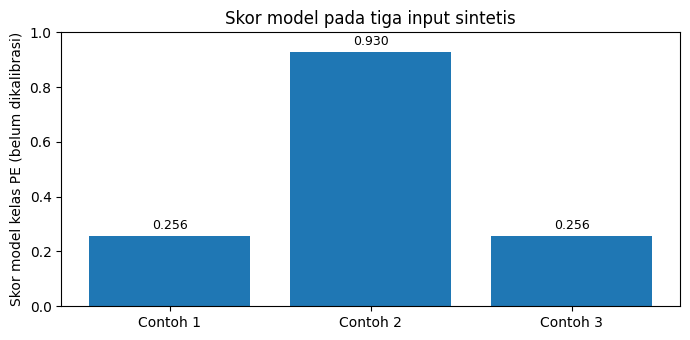

In [11]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar([f'Contoh {i+1}' for i in range(len(score_pe))], score_pe)
ax.set_ylim(0, 1); ax.set_ylabel('Skor model kelas PE (belum dikalibrasi)')
ax.set_title('Skor model pada tiga input sintetis')
for i, value in enumerate(score_pe): ax.text(i, value + 0.025, f'{value:.3f}', ha='center', fontsize=9)
plt.tight_layout(); plt.show()

### E1. Interpretasi grafik
Perbedaan skor hanya menunjukkan **respons model** atas kombinasi nilai input. Tidak boleh menyimpulkan bahwa mengganti suatu input menyebabkan perubahan kondisi medis. Decision Tree juga memiliki jumlah daun terbatas, sehingga beberapa input berbeda dapat menghasilkan skor persis sama.

## F. Inferensi satu record baru
Buat satu baris sintetis dengan nama kolom dan kategori **sama persis** seperti kontrak. Perhatikan cara mengubah objek dictionary menjadi DataFrame sebelum memprediksi.

In [12]:
new_record = {
    'USIA': 27, 'PARITAS': 1, 'JARAK KELAHIRAN': '< 2 tahun',
    'RIW HIPERTENSI': 'Tidak', 'OBESITAS': 'Tidak', 'RIW DM': 'Tidak',
    'RIW HIPERTENSI/PE DALAM KELUARGA': 'Tidak', 'SOSEK RENDAH': '>UMR'
}
X_new = validate_features(pd.DataFrame([new_record]), require_complete=True)
new_pred = int(model.predict(X_new)[0])
new_score = float(model.predict_proba(X_new)[0, idx_pe])
print('Kode label:', new_pred, '| Skor model PE (tidak terkalibrasi):', round(new_score, 4))
display(X_new)

Kode label: 0 | Skor model PE (tidak terkalibrasi): 0.2558


,USIA,PARITAS,JARAK KELAHIRAN,RIW HIPERTENSI,OBESITAS,RIW DM,RIW HIPERTENSI/PE DALAM KELUARGA,SOSEK RENDAH
0,27.0,1.0,< 2 tahun,Tidak,Tidak,Tidak,Tidak,>UMR


## G. Uji kontrak, missing values, dan kategori asing
Perlu dibedakan tiga kondisi: **kolom hilang** (error), **isi fitur numerik/kategori kosong** (pipeline dapat mengimputasi untuk demonstrasi), dan **kategori tidak dikenal** (ditolak di lapisan validasi).

In [13]:
tests=[]
def record_test(name, candidate, expected):
    try:
        checked = validate_features(candidate)
        _ = model.predict(checked)
        outcome = 'PASS'
        detail = 'Input diterima dan dapat diprediksi'
    except (ValueError, TypeError) as exc:
        outcome = 'REJECT'
        detail = str(exc)
    tests.append({'uji': name, 'ekspektasi': expected, 'hasil': outcome, 'sesuai': outcome == expected, 'detail': detail})

record_test('input_valid', X_example.iloc[[0]], 'PASS')
record_test('kolom_hilang', X_example.iloc[[0]].drop(columns=['OBESITAS']), 'REJECT')
record_test('kategori_asing', X_example.iloc[[0]].assign(OBESITAS='Mungkin'), 'REJECT')
record_test('angka_teks_salah', X_example.iloc[[0]].assign(USIA='dua puluh'), 'REJECT')
record_test('usia_tak_wajar_dibanding_data_latihan', X_example.iloc[[0]].assign(USIA=95), 'REJECT')
record_test('nilai_kosong_usia_boleh_dengan_imputer', X_example.iloc[[0]].assign(USIA=np.nan), 'PASS')
record_test('nilai_kosong_kategori_boleh_dengan_imputer', X_example.iloc[[0]].assign(OBESITAS=np.nan), 'PASS')
report_tests = pd.DataFrame(tests)
display(report_tests[['uji','ekspektasi','hasil','sesuai']])
assert report_tests['sesuai'].all()

,uji,ekspektasi,hasil,sesuai
0,input_valid,PASS,PASS,True
1,kolom_hilang,REJECT,REJECT,True
2,kategori_asing,REJECT,REJECT,True
3,angka_teks_salah,REJECT,REJECT,True
4,usia_tak_wajar_dibanding_data_latihan,REJECT,REJECT,True
5,nilai_kosong_usia_boleh_dengan_imputer,PASS,PASS,True
6,nilai_kosong_kategori_boleh_dengan_imputer,PASS,PASS,True


In [14]:
# Formulir publik latihan dapat mewajibkan seluruh input terisi.
try:
    validate_features(X_example.iloc[[0]].assign(USIA=np.nan), require_complete=True)
except ValueError as exc:
    print('PASS: form menolak missing value:', exc)

PASS: form menolak missing value: Formulir membutuhkan seluruh nilai terisi; missing tidak diperbolehkan.


## H. Apa yang terjadi dalam pipeline?
Tahap transformasi numerik dan kategorikal yang disimpan dalam model menghasilkan matriks fitur internal. Pada Praktikum 02 mahasiswa mempelajari konsep feature space, sedangkan **di sini tujuan kita memeriksa konsistensi kontrak inference**; kita tidak melakukan One-Hot Encoding manual lagi.

In [15]:
encoded = preprocessor.transform(X_example)
feature_names = preprocessor.get_feature_names_out()
print('Input (raw):', X_example.shape, '| Setelah transformasi:', encoded.shape)
display(pd.DataFrame(encoded, columns=feature_names).head(3))
assert encoded.shape[0] == len(X_example)
assert encoded.shape[1] == len(feature_names)

Input (raw): (3, 8) | Setelah transformasi: (3, 15)


,num__USIA,num__PARITAS,cat__JARAK KELAHIRAN_< 2 tahun,cat__JARAK KELAHIRAN_> 2 tahun,cat__JARAK KELAHIRAN_anak pertama,cat__RIW HIPERTENSI_Tidak,cat__RIW HIPERTENSI_Ya,cat__OBESITAS_Tidak,cat__OBESITAS_Ya,cat__RIW DM_Tidak,cat__RIW DM_Ya,cat__RIW HIPERTENSI/PE DALAM KELUARGA_Ada,cat__RIW HIPERTENSI/PE DALAM KELUARGA_Tidak,cat__SOSEK RENDAH_<UMR,cat__SOSEK RENDAH_>UMR
0,24.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0
1,35.0,2.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0
2,29.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0


In [16]:
# Decision Tree: beberapa record dengan leaf sama memperoleh skor sama.
tree = model.named_steps['classifier']
leaf_ids = tree.apply(encoded)
leaf_table = pd.DataFrame({'contoh': np.arange(1, len(X_example)+1),
                           'leaf_id': leaf_ids, 'prediksi': pred, 'skor_model_PE': score_pe})
display(leaf_table)

,contoh,leaf_id,prediksi,skor_model_PE
0,1,2,0,0.255837
1,2,5,1,0.930004
2,3,2,0,0.255837


## I. Eksperimen *what-if* pada input sintetis
Eksperimen ini hanya bertujuan **menguji perilaku fungsi prediksi**, bukan menilai efek klinis. Ubah satu fitur, lalu amati label, skor dan `leaf_id` pada Decision Tree yang **sama**.

In [17]:
base_record = X_example.iloc[[0]].copy()
variants = {
    'asli': base_record,
    'usia_lebih_tinggi': base_record.assign(USIA=35.0),
    'paritas_berbeda': base_record.assign(PARITAS=2.0),
    'hipertensi_ya': base_record.assign(**{'RIW HIPERTENSI': 'Ya'}),
    'obesitas_ya': base_record.assign(OBESITAS='Ya')
}
rows=[]
for name, frame in variants.items():
    checked = validate_features(frame, require_complete=True)
    z = preprocessor.transform(checked)
    rows.append({'skenario_sintetis': name,
                 'kelas_prediksi': int(model.predict(checked)[0]),
                 'skor_model_PE': float(model.predict_proba(checked)[0,idx_pe]),
                 'leaf_id': int(tree.apply(z)[0])})
what_if = pd.DataFrame(rows)
display(what_if)

,skenario_sintetis,kelas_prediksi,skor_model_PE,leaf_id
0,asli,0,0.255837,2
1,usia_lebih_tinggi,0,0.255837,2
2,paritas_berbeda,0,0.255837,2
3,hipertensi_ya,1,0.930004,5
4,obesitas_ya,0,0.255837,2


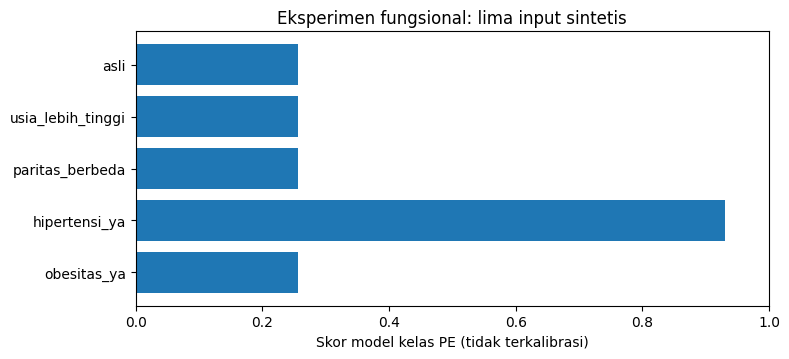

In [18]:
fig, ax = plt.subplots(figsize=(8, 3.7))
ax.barh(what_if['skenario_sintetis'], what_if['skor_model_PE'])
ax.set_xlim(0,1); ax.set_xlabel('Skor model kelas PE (tidak terkalibrasi)')
ax.set_title('Eksperimen fungsional: lima input sintetis')
ax.invert_yaxis(); plt.tight_layout(); plt.show()

## J. Verifikasi konsistensi artefak dengan Praktikum 07
Model yang dipakai aplikasi seharusnya sama **byte-for-byte** dengan model yang sudah diekspor dari Praktikum 07. Jika folder sumber `studi_kasus/model/` juga ada, kita bandingkan SHA-256. Dalam paket ini model tersebut boleh tidak disertakan agar ukuran paket minimal; catatan sumber model tetap ada pada model card.

In [19]:
source_copy = ROOT/'studi_kasus/model/pe_workshop_pipeline.joblib'
if source_copy.exists():
    assert sha256_file(source_copy) == sha256_file(MODEL_FILE)
    print('PASS: checksum model sumber 07 dan deployment 08 identik.')
else:
    print('Salinan sumber 07 tidak disertakan (opsional). Model deployment tetap diaudit menggunakan SHA-256.')
print('Jumlah fitur:',len(FEATURES))
print('Versi pelatihan:',card['sklearn_version'])
print('Asal:',card['origin_module'])

PASS: checksum model sumber 07 dan deployment 08 identik.
Jumlah fitur: 8
Versi pelatihan: 1.7.1
Asal: Praktikum 06 — model terpilih via CV train


In [20]:
# Contoh prediksi ulang: tanpa fit ulang, hasil harus identik.
reloaded = joblib.load(MODEL_FILE)
assert np.array_equal(model.predict(X_example), reloaded.predict(X_example))
assert np.allclose(model.predict_proba(X_example), reloaded.predict_proba(X_example), atol=1e-12)
print('PASS: hasil reload identik untuk seluruh contoh sintetis.')

PASS: hasil reload identik untuk seluruh contoh sintetis.


## K. Membaca evaluasi tersimpan secara tepat
Angka performa di bawah **berasal dari test Praktikum 06** yang tercatat pada model card, **bukan dihitung dari tiga data sintetis** dan **bukan evaluasi ulang model**. Test hanya memiliki 10 kelas positif; tidak ada validasi eksternal atau verifikasi independensi pasien.

In [21]:
metrics = card['test_metrics']
metrics_df = pd.DataFrame([{
    'Accuracy': metrics['accuracy'], 'Precision PE': metrics['precision_PE'],
    'Recall PE': metrics['recall_PE'], 'F1 PE': metrics['f1_PE'],
    'Specificity': metrics['specificity'], 'N positive test': card['n_test_positive']
}])
display(metrics_df.round(3))
print('Confusion matrix: TN =',metrics['TN'], '| FP =',metrics['FP'],
      '| FN =',metrics['FN'], '| TP =',metrics['TP'])
assert sum(metrics[k] for k in ['TN','FP','FN','TP']) == card['test_records']

,Accuracy,Precision PE,Recall PE,F1 PE,Specificity,N positive test
0,0.922,0.467,0.7,0.56,0.939,10


Confusion matrix: TN = 123 | FP = 8 | FN = 3 | TP = 7


### K1. Catatan interpretasi PE
- **False negative** berarti label positif aktual tetapi prediksi model negatif. Dalam konteks data latihan, ini adalah kesalahan klasifikasi, **bukan** penilaian medis pada individu.
- Accuracy tinggi dapat menyesatkan pada data tidak seimbang; perhatikan recall dan precision PE.
- Prediksi skor belum dikalibrasi, dan **nilai 0,50 bukan ambang klinis**.
- Satu baris dataset belum terverifikasi sebagai satu pasien unik. Waktu pencatatan variabel, definisi outcome dan validasi di institusi lain belum dipastikan.

## L. Memperkenalkan Streamlit
**Streamlit** membuat antarmuka web dengan Python. Notebook menangani konsep, analisis dan latihan; `app.py` hanya menangani presentasi, menerima input, dan mengirimkan data ke model tersimpan. App tidak melakukan training ataupun membaca data pasien.

Komponen utama app:
- `st.form`, `st.number_input`, `st.selectbox` untuk delapan fitur.
- `@st.cache_resource` untuk cache artefak model.
- `model.predict`, `predict_proba`, dan tampilan skor.
- Kontrak input dan label peringatan pemakaian pendidikan.

**Mengapa tidak hanya `.ipynb`?** Notebook cukup untuk inferensi di Jupyter. Tetapi untuk membuat aplikasi Streamlit yang bisa dijalankan stabil melalui `streamlit run`, tetap diperlukan file skrip `app.py`. Tidak perlu menyertakan file `08_Inferensi_dan_Streamlit.py` yang hanya mengulang notebook.

In [22]:
# Inspeksi ringan file app, tidak menjalankan server dari Jupyter.
source = APP_FILE.read_text(encoding='utf-8')
checks = {
    'streamlit_import': 'import streamlit as st' in source,
    'form_tersedia': 'st.form(' in source,
    'predict_digunakan': 'model.predict(' in source,
    'skor_digunakan': 'model.predict_proba(' in source,
    'peringatan_pendidikan': 'Bukan alat diagnosis' in source,
}
display(pd.Series(checks, name='cek_aplikasi').to_frame())
assert all(checks.values())
compile(source, str(APP_FILE), 'exec')
print('PASS: kode app.py berhasil diperiksa sintaksnya.')

,cek_aplikasi
streamlit_import,True
form_tersedia,True
predict_digunakan,True
skor_digunakan,True
peringatan_pendidikan,True


PASS: kode app.py berhasil diperiksa sintaksnya.


### L1. Cara menjalankan aplikasi
Buka terminal di **folder hasil ekstraksi** paket dan jalankan:

```bash
python -m pip install -r requirements.txt
python -m streamlit run deployment/versi_2_hasil_studi_kasus/app.py
```

Jika berhasil, terminal menampilkan alamat lokal (umumnya `http://localhost:8501`, tetapi ikuti yang benar-benar ditampilkan). Gunakan data **sintetis**. Jangan mengunggah data pasien ke aplikasi workshop.

**Langkah pengujian manual:**
1. Isi form dengan nilai persis baris pertama `contoh_input.csv`.
2. Klik **Jalankan inferensi contoh**.
3. Cocokkan kode prediksi dan skor dengan `result.iloc[0]` di notebook.
4. Ganti satu kategori, jalankan kembali, dan jelaskan mengapa skor dapat sama.
5. Tinjau panel **Kontrak input** dan **Batasan model**.

In [23]:
command = f'{sys.executable} -m streamlit run deployment/versi_2_hasil_studi_kasus/app.py'
print('Jalankan dari terminal pada folder:', ROOT)
print(command)
print('Streamlit terpasang di kernel ini?', bool(importlib.util.find_spec('streamlit')))
print('Catatan: Notebook tidak perlu mengaktifkan web server otomatis.')

Jalankan dari terminal pada folder: /Users/masaboe/Documents/NGAJAR/ngudiWaluyo2026/Materi/Workshop_From_Data_to_ML
/Users/masaboe/miniconda3/envs/emel/bin/python3.10 -m streamlit run deployment/versi_2_hasil_studi_kasus/app.py
Streamlit terpasang di kernel ini? True
Catatan: Notebook tidak perlu mengaktifkan web server otomatis.


## M. Ekspor laporan inferensi
Ekspor hanya data sintetis agar contoh mudah dibagikan dan dinilai. Manifest berisi metadata, versi, checksum artefak, dan laporan smoke test. Jangan mengekspor label sebagai diagnosis.

In [24]:
pred_path = HASIL/'prediksi_contoh.csv'
result.to_csv(pred_path, index=False)
test_path = HASIL/'laporan_uji_08.csv'
report_tests.to_csv(test_path, index=False)
summary = {
    'module': 'Praktikum 08 — Inferensi dan Streamlit',
    'source_model': card['origin_module'],
    'model_type': card['model_type'],
    'sha256_model': sha256_file(MODEL_FILE),
    'sklearn_version': sklearn.__version__,
    'n_example_records': int(len(result)),
    'feature_names': FEATURES,
    'test_cases': int(len(report_tests)),
    'test_cases_passed': int(report_tests['sesuai'].sum()),
    'intended_use': 'Pendidikan saja; tidak untuk penggunaan klinis'
}
summary_path = HASIL/'ringkasan_inferensi.json'
summary_path.write_text(json.dumps(summary, indent=2, ensure_ascii=False), encoding='utf-8')
display(pd.DataFrame([{'file': p.name, 'byte': p.stat().st_size}
                      for p in [pred_path,test_path,summary_path]]))

,file,byte
0,prediksi_contoh.csv,394
1,laporan_uji_08.csv,646
2,ringkasan_inferensi.json,637


In [25]:
loaded_result = pd.read_csv(pred_path)
assert len(loaded_result) == len(result)
assert loaded_result['kelas_prediksi'].to_numpy().tolist() == pred.tolist()
assert np.allclose(loaded_result['skor_model_PE'].to_numpy(), score_pe, atol=1e-12)
assert json.loads(summary_path.read_text(encoding='utf-8'))['test_cases_passed'] == len(report_tests)
print('PASS: ekspor, reload, dan laporan uji 08 konsisten.')

PASS: ekspor, reload, dan laporan uji 08 konsisten.


## N. Latihan konseptual — 12 soal
Jawab dengan singkat sebelum membuka bagian solusi:

1. Mengapa Modul 08 tidak perlu melakukan training ulang?
2. Apa yang dimaksud pipeline lengkap untuk inferensi?
3. Apa beda output `predict` dan `predict_proba`?
4. Apa arti delapan fitur pada model card?
5. Mengapa nama kolom harus cocok?
6. Apakah skor 0,80 berarti risiko klinis sebesar 80%?
7. Apa risiko `joblib.load` dari file tidak tepercaya?
8. Bagaimana menangani kategori yang tidak ada saat training?
9. Apa akibat missing value saat pipeline berisi imputer?
10. Mengapa 92% accuracy belum membuktikan model cocok untuk rumah sakit?
11. Apa hubungan `app.py`, model `.joblib`, dan notebook `.ipynb`?
12. Mengapa hasil dua aplikasi dari sumber awal (XGBoost vs Decision Tree) tidak boleh dibandingkan langsung?

## O. Latihan praktik — 10 tugas
Selesaikan secara mandiri, lalu bandingkan dengan kode solusi:

1. Hitung jumlah fitur input.
2. Tampilkan kategori yang diizinkan untuk `JARAK KELAHIRAN`.
3. Prediksi baris ketiga contoh sintetis.
4. Cetak skor kelas 0 dan kelas 1 untuk baris pertama.
5. Pastikan semua baris skor berjumlah 1.
6. Buat tabel batch yang memuat `kelas_prediksi` dan `skor_model_PE`.
7. Uji satu kolom hilang dan tangkap error.
8. Uji satu kategori baru yang tidak dikenal.
9. Verifikasi prediksi identik setelah `joblib.load` ulang.
10. Buat salinan CSV prediksi di folder hasil.

## P. Tantangan terapan — 3 tugas
**T1 — Kontrak input.** Buat tiga input sintetis: valid, kolom hilang, dan kategori asing. Tunjukkan apakah validasi berperilaku sesuai.

**T2 — Eksperimen skor.** Ubah satu fitur dari sebuah sampel sintetis dan bandingkan skor serta leaf. Jelaskan keterbatasan interpretasi.

**T3 — Audit aplikasi.** Susun checklist otomatis yang memeriksa keberadaan app, model, model card, daftar fitur, versi library, dan sintaks kode. Jelaskan satu langkah uji manual pada Streamlit.

## Q. Kunci jawaban konseptual
1. Model dari 07 sudah di-*fit*; inferensi hanya menerapkan pipeline untuk sampel baru.
2. Pipeline berisi transformasi (imputer/encoder) dan classifier yang telah dipelajari bersama.
3. `predict` menghasilkan kelas; `predict_proba` menghasilkan skor untuk masing-masing kelas.
4. Delapan fitur ialah kolom wajib input untuk kontrak yang digunakan saat training.
5. Karena pipeline mengacu pada nama dan urutan fitur tertentu; hilang/beda nama dapat gagal atau menghasilkan input salah.
6. **Tidak.** Skor model belum dikalibrasi, bukan peluang risiko klinis.
7. Deserialisasi `.joblib` berpotensi menjalankan kode berbahaya; hanya buka berkas tepercaya.
8. Tolak dan minta perbaikan input; `handle_unknown="ignore"` tidak berarti kategori itu valid.
9. Imputer dapat mengisinya berdasarkan statistik training; tetapi aplikasi dapat memilih menolak input kosong demi kejelasan.
10. Data terbatas, prevalensi tidak seimbang, positif test hanya 10, tanpa validasi eksternal dan audit independensi pasien.
11. Notebook untuk belajar; `.joblib` model tersimpan; `app.py` membangun web dan memanggil model.
12. Definisi model, jumlah fitur, pengolahan data, dan protokol evaluasinya berbeda.

## R. Kunci jawaban latihan kode
Setiap sel di bawah adalah solusi untuk satu atau beberapa tugas bagian O. Kode tidak mengubah model tersimpan dan menggunakan input contoh sintetis.

In [26]:
# O1–O2: fitur dan domain kategori
print('Jumlah fitur:', len(FEATURES))
print('Pilihan JARAK KELAHIRAN:', CATEGORIES['JARAK KELAHIRAN'])

Jumlah fitur: 8
Pilihan JARAK KELAHIRAN: ['< 2 tahun', '> 2 tahun', 'anak pertama']


In [27]:
# O3–O5: baris ketiga, semua skor, uji penjumlahan
third = X_example.iloc[[2]]
print('Prediksi baris ketiga:', int(model.predict(third)[0]))
print('Skor baris pertama [kelas 0, kelas 1]:', model.predict_proba(X_example.iloc[[0]])[0])
assert np.allclose(model.predict_proba(X_example).sum(axis=1), 1)
print('PASS: jumlah skor kelas 0 + kelas 1 = 1.')

Prediksi baris ketiga: 0
Skor baris pertama [kelas 0, kelas 1]: [0.7441631 0.2558369]
PASS: jumlah skor kelas 0 + kelas 1 = 1.


In [28]:
# O6: tabel batch
def batch_predict(frame):
    valid = validate_features(frame)
    out = valid.copy()
    out['kelas_prediksi'] = model.predict(valid)
    out['skor_model_PE'] = model.predict_proba(valid)[:, idx_pe]
    return out

display(batch_predict(examples))

,USIA,PARITAS,JARAK KELAHIRAN,RIW HIPERTENSI,OBESITAS,RIW DM,RIW HIPERTENSI/PE DALAM KELUARGA,SOSEK RENDAH,kelas_prediksi,skor_model_PE
0,24.0,0.0,anak pertama,Tidak,Tidak,Tidak,Tidak,>UMR,0,0.255837
1,35.0,2.0,> 2 tahun,Ya,Ya,Tidak,Ada,<UMR,1,0.930004
2,29.0,1.0,< 2 tahun,Tidak,Ya,Tidak,Tidak,>UMR,0,0.255837


In [29]:
# O7–O8: contoh error kontrak
for bad in [X_example.iloc[[0]].drop(columns=['PARITAS']),
            X_example.iloc[[0]].assign(OBESITAS='Unknown')]:
    try:
        batch_predict(bad)
    except ValueError as exc:
        print('VALIDASI BEKERJA:', exc)

VALIDASI BEKERJA: Kontrak kolom tidak sesuai. Kurang: ['PARITAS']; tambahan: []
VALIDASI BEKERJA: OBESITAS: kategori belum dikenal: ['Unknown']


In [30]:
# O9–O10: konsistensi reload dan ekspor
old_pred = model.predict(X_example)
new_pred_reloaded = joblib.load(MODEL_FILE).predict(X_example)
assert np.array_equal(old_pred, new_pred_reloaded)
copy_path = HASIL/'latihan_prediksi_batch.csv'
batch_predict(X_example).to_csv(copy_path, index=False)
print('PASS:', copy_path.name, '| baris:', len(pd.read_csv(copy_path)))

PASS: latihan_prediksi_batch.csv | baris: 3


## S. Kunci jawaban tantangan terapan

In [31]:
# T1: ketiga kondisi kontrak
cases = {
    'valid': X_example.iloc[[0]],
    'hilang_kolom': X_example.iloc[[0]].drop(columns=['RIW DM']),
    'kategori_asing': X_example.iloc[[0]].assign(**{'RIW DM':'Tidak tahu'})
}
answers=[]
for name, sample in cases.items():
    try:
        checked=validate_features(sample)
        model.predict(checked)
        answer='DITERIMA'
    except ValueError:
        answer='DITOLAK'
    answers.append({'kasus':name, 'hasil':answer})
display(pd.DataFrame(answers))
assert [a['hasil'] for a in answers] == ['DITERIMA','DITOLAK','DITOLAK']

,kasus,hasil
0,valid,DITERIMA
1,hilang_kolom,DITOLAK
2,kategori_asing,DITOLAK


In [32]:
# T2: skor dan leaf pada pasangan input sintetis
pair = pd.concat([
    X_example.iloc[[0]],
    X_example.iloc[[0]].assign(**{'RIW HIPERTENSI':'Ya'})
], ignore_index=True)
pair = validate_features(pair, require_complete=True)
pair_check = pd.DataFrame({
    'variasi':['awal','hipertensi_diubah'],
    'skor_model_PE':model.predict_proba(pair)[:,idx_pe],
    'leaf_id':tree.apply(preprocessor.transform(pair))
})
display(pair_check)
print('Interpretasi: hanya menguji sensitivitas algoritma terhadap input sintetis, bukan hubungan sebab-akibat klinis.')

,variasi,skor_model_PE,leaf_id
0,awal,0.255837,2
1,hipertensi_diubah,0.930004,5


Interpretasi: hanya menguji sensitivitas algoritma terhadap input sintetis, bukan hubungan sebab-akibat klinis.


In [33]:
# T3: audit lengkap artefak
artifact_audit = {
    'app.py': APP_FILE.is_file(),
    'model.joblib': MODEL_FILE.is_file(),
    'model_card.json': CARD_FILE.is_file(),
    'sklearn_consistent': card['sklearn_version'] == sklearn.__version__,
    'feature_contract_consistent': list(model.feature_names_in_) == FEATURES,
    'app_code_compiles': bool(compile(APP_FILE.read_text(encoding='utf-8'),str(APP_FILE),'exec'))
}
display(pd.Series(artifact_audit, name='passed').to_frame())
assert all(artifact_audit.values())
print('Uji manual: inputkan record pertama contoh_input.csv dalam form Streamlit, bandingkan hasil dengan notebook.')

,passed
app.py,True
model.joblib,True
model_card.json,True
sklearn_consistent,True
feature_contract_consistent,True
app_code_compiles,True


Uji manual: inputkan record pertama contoh_input.csv dalam form Streamlit, bandingkan hasil dengan notebook.


## T. Checklist kelulusan dan kesimpulan
- [x] Pipeline hasil Praktikum 07 dapat dimuat **tanpa training ulang**.
- [x] Nama fitur dan kategori sesuai kontrak model.
- [x] Prediksi satu record dan batch menghasilkan kelas serta skor model.
- [x] Kategori asing, kolom hilang dan numerik tidak valid ditangani.
- [x] Ada pengujian output setelah reload model.
- [x] Output sintetis, laporan uji dan metadata berhasil diekspor.
- [x] `app.py` tersedia dan lulus pemeriksaan sintaks.
- [ ] Mahasiswa menjalankan aplikasi Streamlit dan mencocokkan hasil dari terminal masing-masing (perlu dilakukan manual).

**Kesimpulan:** Model dapat didistribusikan sebagai artefak, sedangkan Streamlit menjadi antarmuka inferensi. Namun keberhasilan teknis **tidak sama dengan validasi klinis**. Model workshop tidak boleh dipakai untuk keputusan medis.